In [19]:
# Лабораторна робота 2. Цуркан Еріка. Варіант 7 (17)
!pip install -q minisom mlxtend

Выходные данные были обрезаны до нескольких последних строк (5000).
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetim

In [20]:
   import warnings
   warnings.filterwarnings("ignore")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from minisom import MiniSom
from mlxtend.frequent_patterns import apriori, association_rules

In [22]:
## 1.
customers = pd.read_parquet("customers.parquet")
events = pd.read_csv("events.csv", parse_dates=["event_ts"])

customers.info()
display(customers.head())

print("подій:", len(events), "| абонентів з подіями:", events["abonent_id"].nunique())
print(events["event_type"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   abonent_id         2000 non-null   object 
 1   avg_daily_kwh      2000 non-null   float64
 2   night_share        2000 non-null   float64
 3   seasonality        2000 non-null   float64
 4   weekend_ratio      2000 non-null   float64
 5   stability          2000 non-null   float64
 6   annual_charge_uah  2000 non-null   float64
 7   avg_price_uah_kwh  2000 non-null   float64
 8   voltage_dev_mean   2000 non-null   float64
 9   loss_index_mean    2000 non-null   float64
 10  tariff             2000 non-null   object 
 11  meter_type         2000 non-null   object 
 12  district           2000 non-null   object 
 13  connection_year    2000 non-null   int64  
 14  churned            2000 non-null   int64  
dtypes: float64(9), int64(2), object(4)
memory usage: 234.5+ KB


,abonent_id,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability,annual_charge_uah,avg_price_uah_kwh,voltage_dev_mean,loss_index_mean,tariff,meter_type,district,connection_year,churned
0,AB10001,57.741,0.1081,1.1988,0.6708,0.7170,86122.66,4.086,3.855,5.955,dual_zone,SMART_A,centre,2022,1
1,AB10002,7.643,0.2117,1.4734,0.9465,0.6432,19110.13,6.850,2.361,4.133,business,SMART_A,south,1980,1
2,AB10003,24.032,0.2858,1.8617,1.0839,0.6464,37892.88,4.320,5.360,6.185,single,SMART_A,south,2009,0
3,AB10004,19.065,0.4853,1.5486,1.0091,0.7092,22767.26,3.272,3.023,6.415,dual_zone,SMART_A,north,1983,1
4,AB10005,24.980,0.3202,1.8136,1.0740,0.6841,33082.99,3.628,2.693,10.420,dual_zone,SMART_B,west,2009,0


подій: 4030 | абонентів з подіями: 1364
event_type
complaint         875
outage            779
tariff_change     723
payment_delay     687
contract_query    553
churn             413
Name: count, dtype: int64


In [23]:
## 2. Ознаки для сегментації
# log для avg_daily_kwh, потім стандартизація 5 ознак

features = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability"]

seg_data = customers[features].assign(avg_daily_kwh=np.log(customers["avg_daily_kwh"]))
X = StandardScaler().fit_transform(seg_data)

print("X:", X.shape)
print("середні:", X.mean(axis=0).round(3))
print("ст. відхилення:", X.std(axis=0).round(3))

X: (2000, 5)
середні: [-0.  0.  0.  0.  0.]
ст. відхилення: [1. 1. 1. 1. 1.]


In [24]:
## 3. PCA
# 9 числових показників, eigenvalue > 1 = лишаємо (Кайзер), loadings PC1 і PC2

pca_cols = customers.select_dtypes("number").drop(columns=["connection_year", "churned"]).columns
pca = PCA().fit(StandardScaler().fit_transform(customers[pca_cols]))

variance = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "частка": pca.explained_variance_ratio_,
    "накопичено": pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{i + 1}" for i in range(len(pca_cols))])
display(variance.round(4))

kaiser = (pca.explained_variance_ > 1).sum()
print("компонент за Кайзером:", kaiser, "| разом:", round(variance["накопичено"].iloc[kaiser - 1], 4))

loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]), index=pca_cols, columns=["PC1", "PC2"])
display(loadings.sort_values("PC1", key=abs, ascending=False).round(3))

,eigenvalue,частка,накопичено
PC1,4.0524,0.4500,0.4500
PC2,1.1488,0.1276,0.5776
PC3,1.0160,0.1128,0.6905
PC4,0.9659,0.1073,0.7977
PC5,0.8367,0.0929,0.8907
PC6,0.5265,0.0585,0.9491
PC7,0.3114,0.0346,0.9837
PC8,0.1228,0.0136,0.9973
PC9,0.0240,0.0027,1.0000


компонент за Кайзером: 3 | разом: 0.6905


,PC1,PC2
weekend_ratio,0.857,0.114
annual_charge_uah,-0.834,0.481
seasonality,0.799,0.490
stability,-0.737,-0.473
avg_daily_kwh,-0.721,0.551
avg_price_uah_kwh,-0.689,0.055
night_share,0.667,-0.002
loss_index_mean,-0.025,-0.031
voltage_dev_mean,0.002,-0.365


,інерція,силует
k,,
2,4787.4242,0.5162
3,3552.1890,0.3542
4,2563.4572,0.4124
5,2305.6891,0.3579
6,2088.7668,0.2894
7,1942.5364,0.2650
8,1814.6519,0.2536


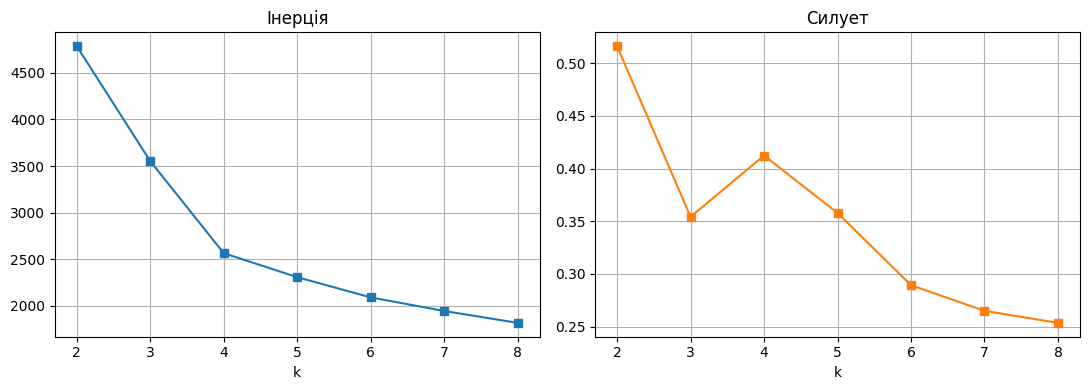

In [25]:
## 4. Кількість кластерів
# інерція й силует для k від 2 до 8

rows = []
for n in range(2, 9):
    km = KMeans(n_clusters=n, n_init=10, random_state=0).fit(X)
    rows.append((n, km.inertia_, silhouette_score(X, km.labels_)))

k_table = pd.DataFrame(rows, columns=["k", "інерція", "силует"]).set_index("k")
display(k_table.round(4))

k_table.plot(subplots=True, layout=(1, 2), figsize=(11, 4), marker="s", legend=False,
             title=["Інерція", "Силует"], grid=True)
plt.tight_layout()
plt.show()

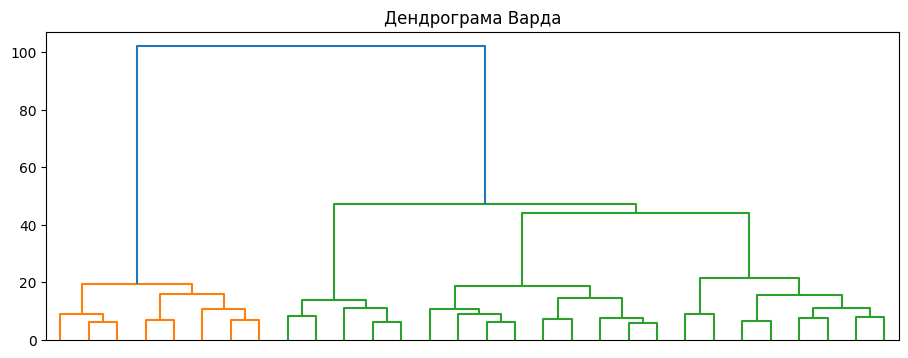

3     2.954
4    22.590
5     2.311
6     0.519
Name: розріз, dtype: float64


In [26]:
## 5. Метод Варда
# дендрограма + довжина розрізу для k від 3 до 6

Z = linkage(X, "ward")

plt.figure(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Дендрограма Варда")
plt.show()

heights = Z[:, 2]
cuts = pd.Series({n: heights[-(n - 1)] - heights[-n] for n in range(3, 7)}, name="розріз")
print(cuts.round(3))

In [27]:
## 6. Порівняння k = 3..6
# лікоть = спад інерції до k / спад після k; + силует, розріз Варда, ARI, розміри сегментів

compare = []
for n in range(3, 7):
    km_labels = KMeans(n_clusters=n, n_init=10, random_state=0).fit_predict(X)
    compare.append({
        "k": n,
        "лікоть": (k_table.loc[n - 1, "інерція"] - k_table.loc[n, "інерція"]) / (k_table.loc[n, "інерція"] - k_table.loc[n + 1, "інерція"]),
        "силует": k_table.loc[n, "силует"],
        "розріз Варда": cuts[n],
        "ARI з Вардом": adjusted_rand_score(km_labels, fcluster(Z, n, "maxclust")),
        "розміри": sorted(np.bincount(km_labels), reverse=True),
    })
    print(f"k = {n}: середні ознак у сегментах")
    display(customers[features].groupby(km_labels).mean().round(3))

display(pd.DataFrame(compare).set_index("k").round(4))

k = 3: середні ознак у сегментах


,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability
0,42.906,0.128,1.183,0.655,0.765
1,14.987,0.344,1.548,1.055,0.708
2,24.362,0.312,1.910,1.083,0.653


k = 4: середні ознак у сегментах


,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability
0,18.356,0.484,1.606,1.025,0.716
1,42.906,0.128,1.183,0.655,0.765
2,24.546,0.306,1.922,1.088,0.652
3,12.820,0.237,1.517,1.076,0.698


k = 5: середні ознак у сегментах


,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability
0,21.737,0.268,1.573,1.077,0.696
1,9.366,0.233,1.520,1.076,0.698
2,42.920,0.128,1.183,0.654,0.765
3,17.969,0.491,1.606,1.023,0.716
4,24.117,0.309,1.973,1.089,0.644


k = 6: середні ознак у сегментах


,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability
0,24.117,0.309,1.973,1.089,0.644
1,57.038,0.129,1.171,0.724,0.785
2,21.693,0.268,1.574,1.077,0.696
3,9.366,0.233,1.520,1.076,0.698
4,31.851,0.128,1.192,0.601,0.749
5,17.969,0.491,1.606,1.023,0.716


,лікоть,силует,розріз Варда,ARI з Вардом,розміри
k,,,,,
3,1.2493,0.3542,2.9539,0.7452,"[991, 526, 483]"
4,3.8357,0.4124,22.5903,0.8171,"[577, 487, 483, 453]"
5,1.1883,0.3579,2.3108,0.7488,"[482, 430, 395, 373, 320]"
6,1.4834,0.2894,0.5192,0.6799,"[430, 395, 373, 319, 271, 212]"


In [28]:
## 6. Обраний поділ
# k = 4 => найкраще за всіма критеріями; порівнюємо k-середні з Вардом

k = 4

labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
ward = fcluster(Z, k, "maxclust")

display(pd.crosstab(labels, ward, rownames=["k-середні"], colnames=["Вард"]))
print("ARI:", round(adjusted_rand_score(labels, ward), 4))

Вард,1,2,3,4
k-середні,,,,
0,0,0,6,447
1,482,0,1,0
2,0,357,27,103
3,0,11,556,10


ARI: 0.8171


In [29]:
## 7. Профіль сегментів
# середні ознак, відтік і частка IND_1985 по сегментах і по всій базі

view = customers[features + ["churned"]].copy()
view["IND_1985"] = customers["meter_type"] == "IND_1985"

seg_profile = view.groupby(labels).mean()
seg_profile.insert(0, "абонентів", np.bincount(labels))

base = view.mean().to_frame("уся база").T
base.insert(0, "абонентів", len(view))

display(pd.concat([seg_profile, base]).round(3))

,абонентів,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability,churned,IND_1985
0,453,18.356,0.484,1.606,1.025,0.716,0.192,0.091
1,483,42.906,0.128,1.183,0.655,0.765,0.176,0.122
2,487,24.546,0.306,1.922,1.088,0.652,0.246,0.115
3,577,12.820,0.237,1.517,1.076,0.698,0.210,0.191
уся база,2000,24.195,0.284,1.555,0.966,0.707,0.206,0.133


топографічна помилка: sigma = 1.5 — 0.166, sigma = 0.5 — 0.733


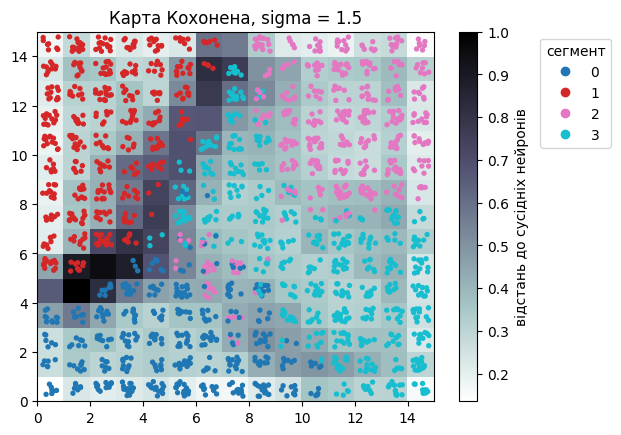

In [30]:
## 8. Карта Кохонена
# топографічна помилка при sigma 1.5 і 0.5

def train_som(sigma):
    som = MiniSom(15, 15, X.shape[1], sigma=sigma, learning_rate=0.5, random_seed=0)
    som.pca_weights_init(X)
    som.train(X, 20000, random_order=True)
    return som

som = train_som(1.5)
som_small = train_som(0.5)
print(f"топографічна помилка: sigma = 1.5 — {som.topographic_error(X):.3f}, sigma = 0.5 — {som_small.topographic_error(X):.3f}")

winners = np.array([som.winner(x) for x in X]) + 0.5
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, size=winners.shape)
mesh = plt.pcolor(som.distance_map().T, cmap="bone_r")
plt.colorbar(mesh, label="відстань до сусідніх нейронів")
points = plt.scatter(*(winners + jitter).T, c=labels, s=8, cmap="tab10")
plt.legend(*points.legend_elements(), title="сегмент", loc="upper left", bbox_to_anchor=(1.25, 1))
plt.title("Карта Кохонена, sigma = 1.5")
plt.show()

In [31]:
## 9. Асоціативні правила
# лишаємо правила з наслідком churned, підтримка 0.05 і 0.10

no_churn = events[events["event_type"] != "churn"]
basket = pd.crosstab(no_churn["abonent_id"], no_churn["event_type"]) > 0  # True, якщо в абонента була хоч одна така подія
basket = basket.reindex(customers["abonent_id"], fill_value=False)  # абоненти без подій — рядок із False
basket["churned"] = customers["churned"].astype(bool).to_numpy()  # рядки йдуть у тому самому порядку, що в customers


def churn_rules(min_support):
    frequent = apriori(basket, min_support=min_support, use_colnames=True)  # набори подій, що трапляються не рідше за поріг
    rules = association_rules(frequent, num_itemsets=len(basket), metric="confidence", min_threshold=0.3)
    rules = rules[rules["consequents"] == frozenset({"churned"})]
    return rules.sort_values("lift", ascending=False)


print("частка churned у базі:", round(basket["churned"].mean(), 4))
for support in [0.05, 0.10]:
    found = churn_rules(support)
    print(f"\nпідтримка {support}: правил {len(found)}")
    print("подій в умові -> правил:", found["antecedents"].apply(len).value_counts().sort_index().to_dict())
    if support == 0.05:
        display(found[["antecedents", "support", "confidence", "lift"]].head(5).round(4))

частка churned у базі: 0.2065

підтримка 0.05: правил 24
подій в умові -> правил: {1: 5, 2: 10, 3: 9}


,antecedents,support,confidence,lift
240,"(contract_query, tariff_change, outage)",0.0520,0.5714,2.7672
149,"(complaint, contract_query, outage)",0.0570,0.5588,2.7062
195,"(payment_delay, complaint, outage)",0.0700,0.5512,2.6692
208,"(complaint, tariff_change, outage)",0.0780,0.5455,2.6414
93,"(contract_query, outage)",0.0715,0.5356,2.5936



підтримка 0.1: правил 8
подій в умові -> правил: {1: 5, 2: 3}


In [32]:
## 10. Пастка
# T-1: |r| по базі > 0.2 і в кожному районі < 0.1 => пастка
# T-2: відношення сезонності поза 0.8..1.2 => пастка
# T-3: різні знаки кореляції => пастка

r_total = customers[["voltage_dev_mean", "loss_index_mean"]].corr().iloc[0, 1]
r_by_district = customers.groupby("district").apply(
    lambda part: part["voltage_dev_mean"].corr(part["loss_index_mean"]))
print("T-1: по базі", round(r_total, 4))
print(r_by_district.round(4))
print("пастка T-1:", abs(r_total) > 0.2 and (r_by_district.abs() < 0.1).all())

old = customers["meter_type"] == "IND_1985"
season_old, season_new = customers.loc[old, "seasonality"].mean(), customers.loc[~old, "seasonality"].mean()
print("\nT-2: IND_1985", round(season_old, 4), "| решта", round(season_new, 4), "| відношення", round(season_old / season_new, 4))
print("пастка T-2:", not 0.8 <= season_old / season_new <= 1.2)

top = customers["abonent_id"].isin(customers.sort_values("annual_charge_uah", ascending=False).head(600)["abonent_id"])
r_big = customers[top]["avg_price_uah_kwh"].corr(customers[top]["churned"])
r_rest = customers[~top]["avg_price_uah_kwh"].corr(customers[~top]["churned"])
print("\nT-3: 600 найбільших", round(r_big, 4), "| решта", round(r_rest, 4))
print("пастка T-3:", np.sign(r_big) != np.sign(r_rest))

T-1: по базі 0.0232
district
centre    0.0185
north     0.0416
south     0.0242
west      0.0111
dtype: float64
пастка T-1: False

T-2: IND_1985 1.5374 | решта 1.5577 | відношення 0.987
пастка T-2: False

T-3: 600 найбільших -0.6652 | решта 0.1649
пастка T-3: True


In [33]:
## Double-check

x = np.asarray(X)
segments = pd.DataFrame({"abonent_id": customers["abonent_id"], "segment_id": labels})

assert x.shape == (2000, 5), "X має містити 2000 абонентів і 5 ознак із features"
assert np.allclose(x.mean(axis=0), 0) and np.allclose(x.std(axis=0), 1, atol=1e-3), "ознаки X не стандартизовано"
assert np.corrcoef(x[:, 0], np.log(customers["avg_daily_kwh"]))[0, 1] > 0.999, "перша колонка X — не логарифм avg_daily_kwh, або customers змінено чи пересортовано"
assert len(segments) == 2000 and segments["abonent_id"].is_unique, "має бути рядок на кожного з 2000 абонентів"
assert pd.api.types.is_integer_dtype(segments["segment_id"]), "segment_id мають бути цілі числа"
assert 3 <= segments["segment_id"].nunique() <= 6, "сегментів має бути від 3 до 6"

segments.to_csv("segments.csv", index=False)
print("усе гаразд:", segments["segment_id"].value_counts().sort_index().to_dict())

усе гаразд: {0: 453, 1: 483, 2: 487, 3: 577}
